# Predicción del abandono de clientes
**Salvador Cruz de Bustos · Ironhack · Machine Learning**

El proyecto analiza si la actividad de un cliente permite anticipar su baja en una compañía de telecomunicaciones iraní. El objetivo es identificar perfiles cuyo servicio podría requerir una revisión.

La variable objetivo es `abandono`: **0 = permanece; 1 = abandona**. Se trata de clasificación binaria: el modelo asigna una de esas dos respuestas.

El análisis sigue tres etapas: preparación de datos, comparación de modelos y evaluación final sobre registros reservados. Los resultados describen esta muestra; no demuestran que una intervención evite las bajas.

## 1. Herramientas y funciones
Se importan las librerías utilizadas en el análisis. pandas permite trabajar con tablas; Matplotlib y Seaborn permiten representar los datos; scikit-learn contiene los modelos y las métricas.

Las operaciones repetidas se encuentran en `funciones.py`, como preparar variables, entrenar y evaluar. `formatear_metricas()` presenta accuracy, precision y recall como porcentajes; F1 conserva su escala de 0 a 1. Los valores usados para calcular y ordenar no se modifican.

Las celdas se ejecutan en orden. La carpeta `modelos` contiene el modelo entrenado y su escalador.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from funciones import limpiar_columnas, preparar_variables, balancear, evaluar_modelo
from funciones import entrenar_evaluar, crear_modelos, predecir_clientes, formatear_metricas

Path("modelos").mkdir(exist_ok=True)
plt.rcParams["figure.figsize"] = (9, 4)
print("pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)

pandas: 2.2.3 scikit-learn: 1.8.0


## 2. Cargar y entender los datos
Se lee `data/Customer_Churn.csv` y se cambian los nombres de las columnas a español para facilitar su interpretación. El archivo original no se modifica.

`head()` muestra las primeras filas, `info()` indica los tipos de datos y `describe()` resume los valores numéricos. También se cuentan los datos que faltan.

Diccionario de variables:

| Columna | Qué significa |
|---|---|
| fallos_llamada | Número de fallos de llamadas |
| quejas | 0: sin queja; 1: con queja |
| meses_suscripcion | Antigüedad del cliente en meses |
| nivel_gasto | Categoría de gasto; no es una cantidad en euros |
| segundos_uso | Tiempo total de llamadas |
| numero_llamadas | Cantidad de llamadas |
| numero_sms | Cantidad de mensajes de texto |
| numeros_distintos | Números diferentes a los que llama |
| grupo_edad | Categoría de edad de 1 a 5 |
| plan_tarifa | 1: prepago; 2: contrato |
| estado | 1: activo; 2: inactivo |
| edad | Edad registrada en el archivo |
| valor_cliente | Valor calculado del cliente |
| abandono | Variable objetivo: 0 permanece, 1 abandona |

Fuente: [Iranian Churn, UCI (2020)](https://doi.org/10.24432/C5JW3Z), licencia CC BY 4.0. Según UCI, las entradas recogen los primeros nueve meses y el abandono se observa al terminar el mes doce. Este intervalo permite plantear una predicción anterior a la baja.

In [2]:
original = pd.read_csv("data/Customer_Churn.csv")
df = limpiar_columnas(original)
print("Filas y columnas:", df.shape)
display(df.head())
df.info()
display(pd.DataFrame({"Nulos": df.isna().sum(), "Valores distintos": df.nunique()}))
display(df.describe())

Filas y columnas: (3150, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   fallos_llamada     3150 non-null   int64  
 1   quejas             3150 non-null   int64  
 2   meses_suscripcion  3150 non-null   int64  
 3   nivel_gasto        3150 non-null   int64  
 4   segundos_uso       3150 non-null   int64  
 5   numero_llamadas    3150 non-null   int64  
 6   numero_sms         3150 non-null   int64  
 7   numeros_distintos  3150 non-null   int64  
 8   grupo_edad         3150 non-null   int64  
 9   plan_tarifa        3150 non-null   int64  
 10  estado             3150 non-null   int64  
 11  edad               3150 non-null   int64  
 12  valor_cliente      3150 non-null   float64
 13  abandono           3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 344.7 KB


,fallos_llamada,quejas,meses_suscripcion,nivel_gasto,segundos_uso,numero_llamadas,numero_sms,numeros_distintos,grupo_edad,plan_tarifa,estado,edad,valor_cliente,abandono
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


,Nulos,Valores distintos
fallos_llamada,0,37
quejas,0,2
meses_suscripcion,0,45
nivel_gasto,0,11
segundos_uso,0,1756
numero_llamadas,0,242
numero_sms,0,405
numeros_distintos,0,92
grupo_edad,0,5
plan_tarifa,0,2


,fallos_llamada,quejas,meses_suscripcion,nivel_gasto,segundos_uso,numero_llamadas,numero_sms,numeros_distintos,grupo_edad,plan_tarifa,estado,edad,valor_cliente,abandono
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


## 3. Limpieza y balance de clases
Se identifican **300 copias exactas de filas completas**. Se conserva una copia por registro antes de separar los datos: el conjunto pasa de **3.150 a 2.850 filas**. Esta decisión evita distribuir copias exactas entre entrenamiento y evaluación.

La ausencia de identificadores impide confirmar que las repeticiones sean errores o correspondan al mismo cliente. Eliminarlas cambia el peso de algunos perfiles y no garantiza independencia entre clientes.

No hay valores nulos. Los valores elevados se conservan cuando no existe evidencia para corregirlos. En particular, siete registros tienen nivel de gasto 10, aunque la fuente describe un rango de 0 a 9.

Quedan **2.404 permanencias y 446 abandonos (15,65 %)**. Esta diferencia justifica comparar el entrenamiento original con técnicas de balanceo.

Se conservan 28 filas con entradas iguales y respuestas distintas: no existe información suficiente para decidir qué respuesta corregir.

In [3]:
print("Repeticiones posteriores a la primera:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Tamaño después de quitar copias exactas:", df.shape)
print("Perfiles iguales con distinta respuesta:", df.duplicated(subset=df.columns[:-1], keep=False).sum())
print("Registros con nivel_gasto = 10:", (df["nivel_gasto"] == 10).sum())
display(pd.DataFrame({"Clientes": df["abandono"].value_counts(),
                      "Porcentaje": df["abandono"].value_counts(normalize=True) * 100}))

Repeticiones posteriores a la primera: 300
Tamaño después de quitar copias exactas: (2850, 14)
Perfiles iguales con distinta respuesta: 28
Registros con nivel_gasto = 10: 7


,Clientes,Porcentaje
abandono,,
0,2404,84.350877
1,446,15.649123


## 4. Preparación de variables y división de datos
`preparar_variables()` realiza cuatro transformaciones:

- Elimina `grupo_edad`: en este archivo repite los mismos cinco grupos representados por `edad`.
- Elimina `valor_cliente`: su fórmula no está disponible para calcularlo en un cliente nuevo.
- Convierte tarifa y estado de códigos 1/2 a códigos 0/1.
- Crea `duracion_media_llamada`: segundos de uso divididos entre llamadas. Vale cero cuando no hay llamadas ni uso; previamente se comprueba que no existen filas con uso positivo y cero llamadas.

Las **12 variables predictoras se guardan en `X`** y la respuesta en **`y`**. La respuesta nunca forma parte de las entradas.

| Conjunto | Registros | Función |
|---|---:|---|
| Entrenamiento | 1.710 (60 %) | Aprender patrones |
| Validación | 570 (20 %) | Comparar configuraciones y elegir |
| Test | 570 (20 %) | Evaluar al final el modelo elegido |

`random_state=0` permite repetir el reparto. `stratify` conserva aproximadamente la proporción de bajas en cada conjunto. La segunda división toma el 25 % del 80 % restante, equivalente al 20 % del total.

In [4]:
print("Uso positivo sin llamadas:", ((df["numero_llamadas"] == 0) & (df["segundos_uso"] > 0)).sum())
X = preparar_variables(df)
y = df["abandono"]
X_desarrollo, X_test, y_desarrollo, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_desarrollo, y_desarrollo, test_size=0.25, random_state=0, stratify=y_desarrollo)
print("Entrenamiento, validación y test:", X_train.shape, X_val.shape, X_test.shape)
display(pd.DataFrame({"Entrenamiento (%)": y_train.value_counts(normalize=True)*100,
                      "Validación (%)": y_val.value_counts(normalize=True)*100}))

Uso positivo sin llamadas: 0
Entrenamiento, validación y test: (1710, 12) (570, 12) (570, 12)


,Entrenamiento (%),Validación (%)
abandono,,
0,84.327485,84.385965
1,15.672515,15.614035


## 5. Exploración del entrenamiento
La exploración utiliza exclusivamente entrenamiento. Las respuestas del test quedan reservadas para la evaluación final.

El primer gráfico muestra el balance de clases. El segundo compara el porcentaje de abandono de los perfiles con y sin quejas. `count` indica el número de registros; `porcentaje_abandono` expresa las bajas por cada 100 perfiles del grupo.

El mapa de correlación muestra asociaciones entre columnas: rojo indica que suelen aumentar juntas y azul que suelen variar en sentido contrario. Una asociación no demuestra que una variable cause la baja.

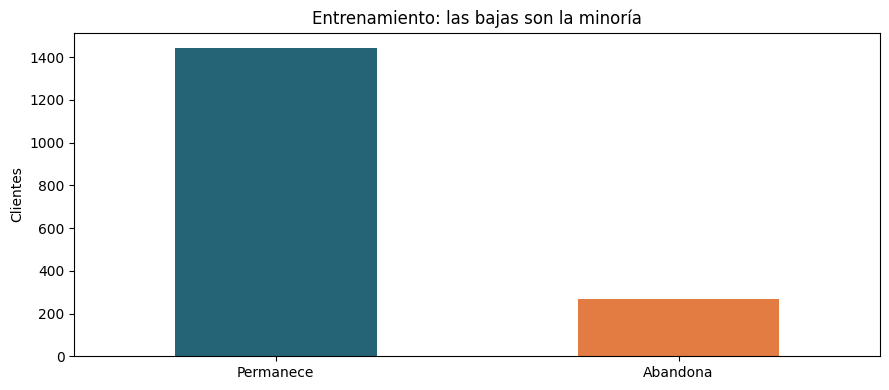

,count,porcentaje_abandono
quejas,,
0,1577,10.08
1,133,81.95


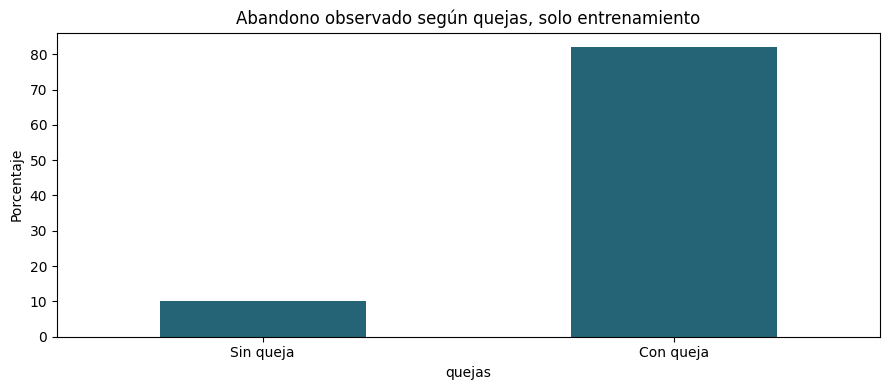

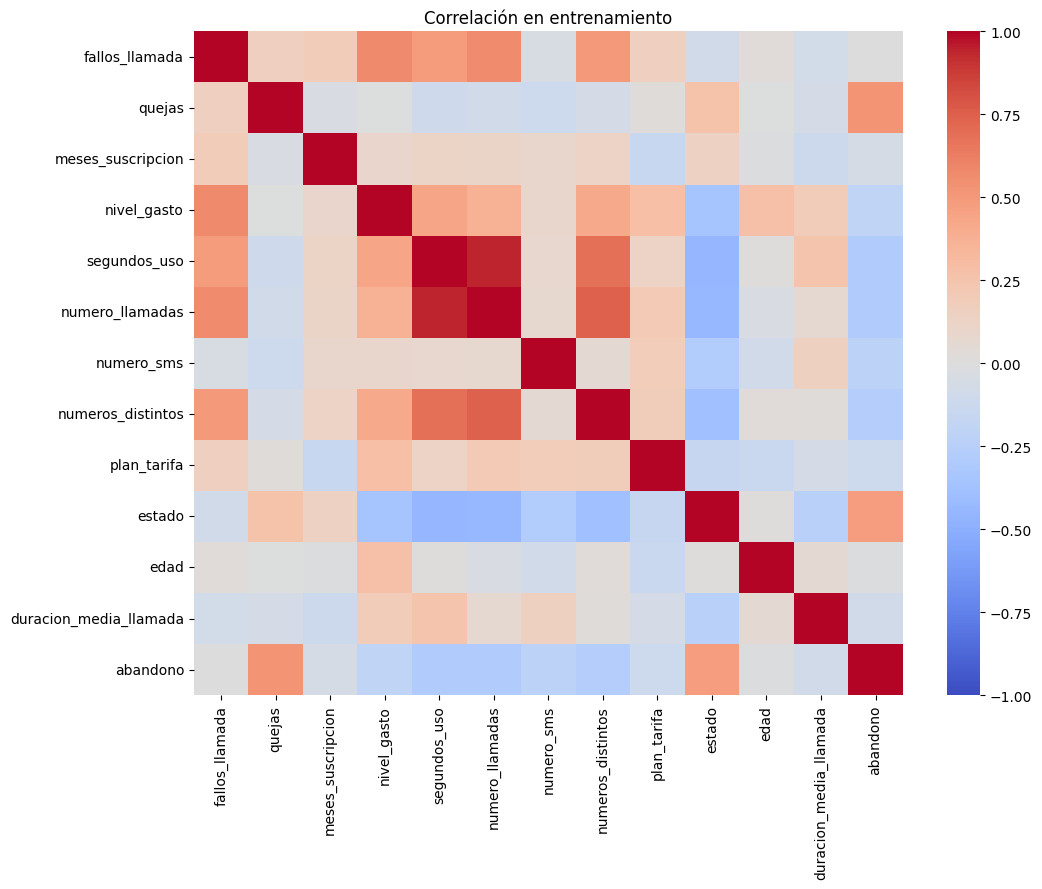

In [5]:
exploracion = X_train.copy()
exploracion["abandono"] = y_train
balance = y_train.value_counts().sort_index()
balance.index = ["Permanece", "Abandona"]
balance.plot(kind="bar", color=["#256377", "#E37C43"], rot=0)
plt.title("Entrenamiento: las bajas son la minoría")
plt.ylabel("Clientes")
plt.tight_layout()
plt.show()
resumen_quejas = exploracion.groupby("quejas")["abandono"].agg(["count", "mean"])
resumen_quejas["porcentaje_abandono"] = resumen_quejas["mean"] * 100
display(resumen_quejas[["count", "porcentaje_abandono"]].round(2))
resumen_quejas["porcentaje_abandono"].plot(kind="bar", color="#256377", rot=0)
plt.xticks([0, 1], ["Sin queja", "Con queja"])
plt.title("Abandono observado según quejas, solo entrenamiento")
plt.ylabel("Porcentaje")
plt.tight_layout()
plt.show()
plt.figure(figsize=(11, 9))
sns.heatmap(exploracion.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlación en entrenamiento")
plt.tight_layout()
plt.show()

## 6. Normalización
Las variables tienen escalas distintas: la edad puede valer 30 y el uso varios miles de segundos. `MinMaxScaler` coloca las entradas de entrenamiento en una escala comparable entre 0 y 1.

`fit` calcula los mínimos y máximos exclusivamente con entrenamiento. `transform` aplica esos mismos valores a entrenamiento y validación.

**Todos los modelos utilizan las mismas entradas normalizadas.** El escalador se ajusta una vez porque los modelos reciben las mismas filas y columnas. Un nuevo registro puede quedar fuera de 0–1 si supera los rangos observados durante el ajuste.

In [6]:
escalador = MinMaxScaler()
escalador.fit(X_train)
X_train_norm = pd.DataFrame(escalador.transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_norm = pd.DataFrame(escalador.transform(X_val), columns=X_val.columns, index=X_val.index)
display(X_train_norm.head())

,fallos_llamada,quejas,meses_suscripcion,nivel_gasto,segundos_uso,numero_llamadas,numero_sms,numeros_distintos,plan_tarifa,estado,edad,duracion_media_llamada
810,0.228571,0.0,0.909091,0.1,0.348528,0.397638,0.029126,0.134021,0.0,0.0,0.375,0.181406
1866,0.000000,0.0,0.840909,0.0,0.033569,0.055118,0.001942,0.103093,0.0,1.0,0.250,0.126050
2917,0.257143,0.0,0.954545,0.0,0.059776,0.102362,0.054369,0.113402,0.0,1.0,0.375,0.120862
403,0.228571,0.0,0.727273,0.0,0.236631,0.228346,0.000000,0.309278,0.0,0.0,0.000,0.214476
1131,0.000000,0.0,0.750000,0.0,0.022556,0.015748,0.013592,0.041237,0.0,0.0,0.750,0.296440


## 7. Modelos de referencia y métricas
Se entrenan ocho clasificadores: KNN, regresión logística, árbol de decisión, Bagging, Pasting, Random Forest, Gradient Boosting y AdaBoost.

KNN compara perfiles similares; regresión logística ofrece una referencia lineal; el árbol aprende reglas. Los cinco métodos restantes combinan varios modelos. La comparación permite comprobar su comportamiento sobre los mismos datos.

`entrenar_evaluar()` ajusta con `fit`, predice validación con `predict` y calcula las métricas.

| Métrica | Interpretación |
|---|---|
| Accuracy | Porcentaje de registros clasificados correctamente |
| Precision | Porcentaje de alertas que corresponden a bajas reales |
| Recall | Porcentaje de bajas reales detectadas |
| F1 | Equilibrio entre precision y recall; puntuación de 0 a 1 |

El criterio de selección es **F1 de validación**. Se busca un equilibrio entre detectar bajas y generar falsas alarmas. Ante un empate, se prioriza recall; el nombre solo ordena un empate completo.

La referencia «Siempre permanece» permite comprobar si el modelo aporta algo más que acertar la clase mayoritaria. En las tablas, **TP** representa bajas detectadas, **FN** bajas no detectadas, **FP** falsas alarmas y **TN** permanencias acertadas.

In [7]:
resultados = []
modelos = {}
referencia = evaluar_modelo("Siempre permanece", y_val, np.zeros(len(y_val), dtype=int))
display(formatear_metricas(pd.DataFrame([referencia])))
for nombre, modelo in crear_modelos().items():
    etiqueta = nombre + " | Original"
    modelo, resultado = entrenar_evaluar(etiqueta, modelo, X_train_norm, y_train, X_val_norm, y_val)
    modelos[etiqueta] = modelo
    resultados.append(resultado)
display(formatear_metricas(pd.DataFrame(resultados).sort_values("F1", ascending=False)))

,Modelo,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Siempre permanece,"84,39 %","0,00 %","0,00 %","0,000",481,0,89,0


,Modelo,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
5,Random Forest | Original,"95,61 %","94,44 %","76,40 %","0,845",477,4,21,68
6,Gradient Boosting | Original,"94,91 %","90,54 %","75,28 %","0,822",474,7,22,67
3,Bagging | Original,"94,39 %","88,00 %","74,16 %","0,805",472,9,23,66
4,Pasting | Original,"93,51 %","82,50 %","74,16 %","0,781",467,14,23,66
0,KNN | Original,"93,51 %","83,33 %","73,03 %","0,778",468,13,24,65
7,AdaBoost | Original,"93,16 %","81,25 %","73,03 %","0,769",466,15,24,65
2,Árbol de decisión | Original,"92,63 %","79,01 %","71,91 %","0,753",464,17,25,64
1,Regresión logística | Original,"90,70 %","92,86 %","43,82 %","0,595",478,3,50,39


## 8. Comparación del balanceo
El entrenamiento contiene 1.442 permanencias y 268 bajas. Se evalúan dos formas de cambiar esa proporción:

- **Oversampling:** repite bajas con `resample` hasta igualar las clases, con 1.442 registros de cada una. Se aplica a los ocho modelos.
- **Undersampling:** reduce las permanencias hasta 268 registros, igualando las clases. Se prueba con regresión logística; implica descartar información del entrenamiento.

Solo se modifica entrenamiento. Validación y test mantienen su distribución original. El balanceo se compara, no se da por beneficioso de antemano.

No se aplica SMOTE porque una interpolación directa podría producir valores intermedios en variables binarias como quejas. `Original` indica ausencia de balanceo y `Oversampling`, repetición de ejemplos; repetir registros no añade información nueva.

In [8]:
X_over, y_over = balancear(X_train_norm, y_train, metodo="over")
display(pd.DataFrame({"Original": y_train.value_counts(), "Oversampling": y_over.value_counts()}))
for nombre, modelo in crear_modelos().items():
    etiqueta = nombre + " | Oversampling"
    modelo, resultado = entrenar_evaluar(etiqueta, modelo, X_over, y_over, X_val_norm, y_val)
    modelos[etiqueta] = modelo
    resultados.append(resultado)
X_under, y_under = balancear(X_train_norm, y_train, metodo="under")
etiqueta = "Regresión logística | Undersampling"
modelo, resultado = entrenar_evaluar(etiqueta, LogisticRegression(max_iter=1000, random_state=0),
                                     X_under, y_under, X_val_norm, y_val)
modelos[etiqueta] = modelo
resultados.append(resultado)
comparacion_balance = pd.DataFrame(resultados).sort_values("F1", ascending=False)
display(formatear_metricas(comparacion_balance))

,Original,Oversampling
abandono,,
0,1442,1442
1,268,1442


,Modelo,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
5,Random Forest | Original,"95,61 %","94,44 %","76,40 %","0,845",477,4,21,68
13,Random Forest | Oversampling,"94,74 %","80,41 %","87,64 %","0,839",462,19,11,78
11,Bagging | Oversampling,"94,39 %","80,00 %","85,39 %","0,826",462,19,13,76
6,Gradient Boosting | Original,"94,91 %","90,54 %","75,28 %","0,822",474,7,22,67
12,Pasting | Oversampling,"94,21 %","80,43 %","83,15 %","0,818",463,18,15,74
14,Gradient Boosting | Oversampling,"93,68 %","75,24 %","88,76 %","0,814",455,26,10,79
8,KNN | Oversampling,"93,33 %","73,39 %","89,89 %","0,808",452,29,9,80
3,Bagging | Original,"94,39 %","88,00 %","74,16 %","0,805",472,9,23,66
10,Árbol de decisión | Oversampling,"92,81 %","73,08 %","85,39 %","0,788",453,28,13,76
4,Pasting | Original,"93,51 %","82,50 %","74,16 %","0,781",467,14,23,66


## 9. Ajuste con Grid Search
Se ajusta Random Forest por su buen resultado de referencia en validación. Los parámetros controlan cómo se construye el bosque:

| Parámetro | Función |
|---|---|
| n_estimators | Número de árboles |
| max_depth | Profundidad máxima de cada árbol |
| max_leaf_nodes | Máximo de hojas o resultados finales por árbol |

`GridSearchCV` evalúa **18 combinaciones**. `None` significa que ese límite no se establece.

La validación cruzada de cinco partes (`cv=5`) aprende con cuatro partes de entrenamiento y comprueba con la restante, rotando las partes. Se selecciona el mejor F1 medio.

Las búsquedas utilizan entrenamiento sin balancear. Repetir filas antes de las divisiones internas podría colocar copias en aprendizaje y comprobación.

**Limitación del procedimiento:** el escalador se ajusta con todo entrenamiento antes de la validación cruzada, siguiendo el flujo aplicado en clase. Las búsquedas se restringen a Random Forest, cuyos cortes no dependen de las unidades de medida. La validación cruzada no sustituye la comprobación independiente final: el test permanece fuera del ajuste.

In [9]:
parametros_grid = {"n_estimators": [50, 100, 200],
                   "max_depth": [5, 10, None],
                   "max_leaf_nodes": [20, None]}
busqueda_grid = GridSearchCV(RandomForestClassifier(random_state=0),
                             param_grid=parametros_grid, cv=5, scoring="f1", n_jobs=1)
busqueda_grid.fit(X_train_norm, y_train)
print("Mejores parámetros Grid:", busqueda_grid.best_params_)
print("F1 medio CV:", busqueda_grid.best_score_)

Mejores parámetros Grid: {'max_depth': None, 'max_leaf_nodes': None, 'n_estimators': 100}
F1 medio CV: 0.8459227516898782


## 10. Ajuste con Randomized Search
`RandomizedSearchCV` evalúa **10 combinaciones de las 36 posibles**. La selección aleatoria permite reducir el número de pruebas respecto a una búsqueda exhaustiva.

Se utilizan cinco partes internas, F1 como criterio y una semilla fija. `best_params_` muestra la configuración seleccionada.

Las configuraciones obtenidas por ambas búsquedas se entrenan con y sin oversampling y se incorporan a la comparación de validación. Una búsqueda no garantiza una mejora frente al modelo de referencia.

In [10]:
parametros_random = {"n_estimators": [50, 100, 200, 300],
                     "max_depth": [5, 10, None],
                     "max_leaf_nodes": [20, 50, None]}
busqueda_random = RandomizedSearchCV(RandomForestClassifier(random_state=0),
                                     param_distributions=parametros_random, n_iter=10,
                                     cv=5, scoring="f1", random_state=0, n_jobs=1)
busqueda_random.fit(X_train_norm, y_train)
print("Mejores parámetros Randomized:", busqueda_random.best_params_)
print("F1 medio CV:", busqueda_random.best_score_)
for metodo, busqueda in [("Grid", busqueda_grid), ("Randomized", busqueda_random)]:
    for balanceo, entradas, respuestas in [("Original", X_train_norm, y_train), ("Oversampling", X_over, y_over)]:
        etiqueta = "Random Forest " + metodo + " | " + balanceo
        modelo = RandomForestClassifier(random_state=0, **busqueda.best_params_)
        modelo, resultado = entrenar_evaluar(etiqueta, modelo, entradas, respuestas, X_val_norm, y_val)
        modelos[etiqueta] = modelo
        resultados.append(resultado)
display(formatear_metricas(pd.DataFrame(resultados).sort_values("F1", ascending=False)))

Mejores parámetros Randomized: {'n_estimators': 200, 'max_leaf_nodes': None, 'max_depth': 10}
F1 medio CV: 0.835279006707578


,Modelo,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
19,Random Forest Randomized | Original,"95,79 %","94,52 %","77,53 %","0,852",477,4,20,69
17,Random Forest Grid | Original,"95,61 %","93,24 %","77,53 %","0,847",476,5,20,69
5,Random Forest | Original,"95,61 %","94,44 %","76,40 %","0,845",477,4,21,68
13,Random Forest | Oversampling,"94,74 %","80,41 %","87,64 %","0,839",462,19,11,78
18,Random Forest Grid | Oversampling,"95,09 %","86,75 %","80,90 %","0,837",470,11,17,72
20,Random Forest Randomized | Oversampling,"94,39 %","78,79 %","87,64 %","0,830",460,21,11,78
11,Bagging | Oversampling,"94,39 %","80,00 %","85,39 %","0,826",462,19,13,76
6,Gradient Boosting | Original,"94,91 %","90,54 %","75,28 %","0,822",474,7,22,67
12,Pasting | Oversampling,"94,21 %","80,43 %","83,15 %","0,818",463,18,15,74
14,Gradient Boosting | Oversampling,"93,68 %","75,24 %","88,76 %","0,814",455,26,10,79


## 11. Selección y comprobación del sobreajuste
Las 21 configuraciones se ordenan por F1 de validación. Se selecciona **Random Forest ajustado con Randomized Search, sin balanceo**, con 200 árboles y profundidad máxima de 10.

El modelo obtiene **F1 = 0,852 en validación**. La etiqueta `Original` indica que no se aplicó balanceo; las entradas sí están normalizadas.

Su F1 de entrenamiento es **0,974**. La diferencia respecto a validación sugiere sobreajuste: parte de los patrones aprendidos funciona mejor en los registros conocidos que en otros registros.

El gráfico muestra las ocho mejores configuraciones de validación. El test no interviene en esta selección.

Elegido por validación: Random Forest Randomized | Original


,Modelo,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Random Forest Randomized | Original,"95,79 %","94,52 %","77,53 %","0,852",477,4,20,69
1,Random Forest Grid | Original,"95,61 %","93,24 %","77,53 %","0,847",476,5,20,69
2,Random Forest | Original,"95,61 %","94,44 %","76,40 %","0,845",477,4,21,68
3,Random Forest | Oversampling,"94,74 %","80,41 %","87,64 %","0,839",462,19,11,78
4,Random Forest Grid | Oversampling,"95,09 %","86,75 %","80,90 %","0,837",470,11,17,72
5,Random Forest Randomized | Oversampling,"94,39 %","78,79 %","87,64 %","0,830",460,21,11,78
6,Bagging | Oversampling,"94,39 %","80,00 %","85,39 %","0,826",462,19,13,76
7,Gradient Boosting | Original,"94,91 %","90,54 %","75,28 %","0,822",474,7,22,67
8,Pasting | Oversampling,"94,21 %","80,43 %","83,15 %","0,818",463,18,15,74
9,Gradient Boosting | Oversampling,"93,68 %","75,24 %","88,76 %","0,814",455,26,10,79


,Modelo,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Entrenamiento original,"99,18 %","98,11 %","96,64 %","0,974",1437,5,9,259
1,Validación,"95,79 %","94,52 %","77,53 %","0,852",477,4,20,69


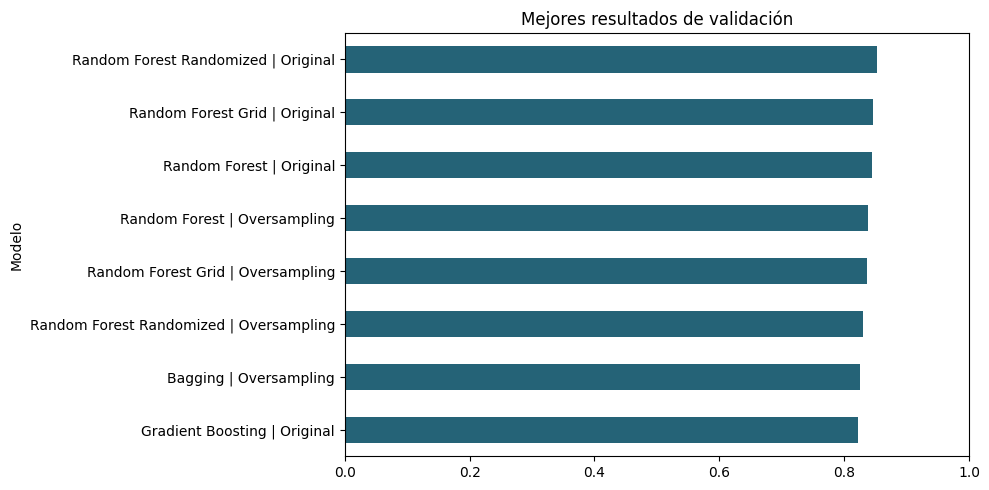

In [11]:
comparativa = pd.DataFrame(resultados).sort_values(["F1", "Recall", "Modelo"], ascending=[False, False, True]).reset_index(drop=True)
display(formatear_metricas(comparativa))
nombre_final = comparativa.loc[0, "Modelo"]
modelo_final = modelos[nombre_final]
print("Elegido por validación:", nombre_final)
revision = pd.DataFrame([
    evaluar_modelo("Entrenamiento original", y_train, modelo_final.predict(X_train_norm)),
    evaluar_modelo("Validación", y_val, modelo_final.predict(X_val_norm))])
display(formatear_metricas(revision))
comparativa.head(8).sort_values("F1").plot.barh(x="Modelo", y="F1", legend=False, color="#256377", figsize=(10, 5))
plt.xlim(0, 1)
plt.title("Mejores resultados de validación")
plt.tight_layout()
plt.show()

## 12. Importancia de variables y diagnóstico de estado
Se calculan las importancias del **Random Forest de referencia sin balanceo**, no del modelo ajustado final. La importancia resume cuánto contribuye cada variable a reducir la impureza de los árboles. No representa una probabilidad de abandono ni demuestra causalidad.

Quejas, segundos de uso y estado ocupan las primeras posiciones. Las importancias pueden verse afectadas por variables correlacionadas y por el número de valores distintos de cada columna.

Una prueba con la misma configuración, eliminando `estado`, reduce el F1 de validación de **0,845 a 0,758**. La variable aporta información; su disponibilidad antes de la baja debe verificarse en una aplicación real.

Este diagnóstico utiliza validación y no modifica la selección del modelo final.

quejas                    19.67
segundos_uso              12.56
estado                    12.38
numero_llamadas           11.00
duracion_media_llamada    11.00
meses_suscripcion         10.18
numeros_distintos          6.67
fallos_llamada             5.66
numero_sms                 5.18
edad                       3.66
nivel_gasto                1.84
plan_tarifa                0.20
Name: Importancia (%), dtype: float64

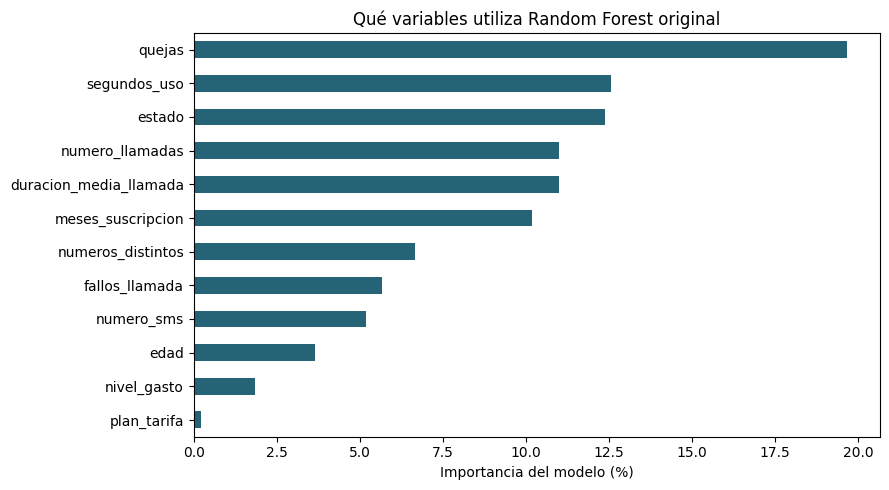

,Modelo,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Random Forest con estado,"95,61 %","94,44 %","76,40 %","0,845",477,4,21,68
1,Random Forest sin estado | Diagnóstico,"93,51 %","90,62 %","65,17 %","0,758",475,6,31,58


In [12]:
bosque = modelos["Random Forest | Original"]
importancias = pd.Series(bosque.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display((importancias * 100).round(2).rename("Importancia (%)"))
(importancias * 100).sort_values().plot(kind="barh", color="#256377", figsize=(9, 5))
plt.title("Qué variables utiliza Random Forest original")
plt.xlabel("Importancia del modelo (%)")
plt.tight_layout()
plt.show()
bosque_sin_estado, resultado_sin_estado = entrenar_evaluar(
    "Random Forest sin estado | Diagnóstico", RandomForestClassifier(n_estimators=100, max_depth=10, random_state=0),
    X_train_norm.drop(columns="estado"), y_train, X_val_norm.drop(columns="estado"), y_val)
diagnostico = pd.DataFrame([evaluar_modelo("Random Forest con estado", y_val, bosque.predict(X_val_norm)), resultado_sin_estado])
display(formatear_metricas(diagnostico))

## 13. Evaluación final con test
El modelo seleccionado se evalúa sobre **570 registros reservados**. Las entradas se transforman con el escalador ajustado en entrenamiento.

| Resultado | Registros |
|---|---:|
| Permanencias clasificadas correctamente | 473 |
| Permanencias marcadas como bajas: falsas alarmas | 8 |
| Bajas no detectadas | 18 |
| Bajas detectadas | 71 |

El modelo detecta **71 de 89 bajas** y genera **8 falsas alarmas**. Estos resultados no se utilizan para volver a elegir parámetros. La tabla incluye la referencia «Siempre permanece» y la matriz permite identificar los dos tipos de error.

,Modelo,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Random Forest Randomized | Original,"95,44 %","89,87 %","79,78 %","0,845",473,8,18,71
1,Siempre permanece,"84,39 %","0,00 %","0,00 %","0,000",481,0,89,0


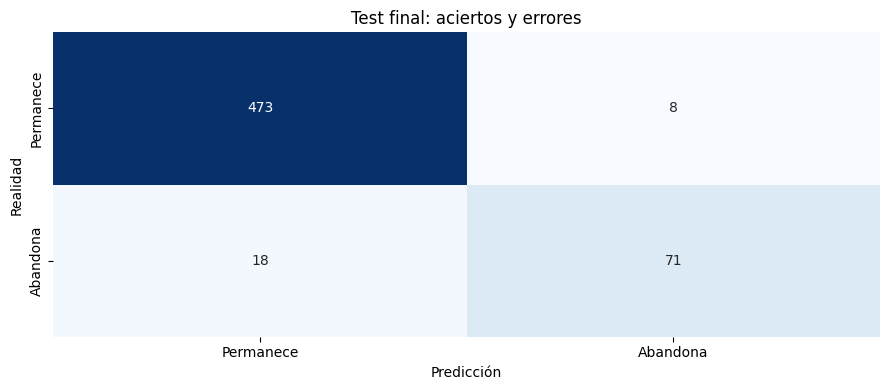

In [13]:
X_test_norm = pd.DataFrame(escalador.transform(X_test), columns=X_test.columns, index=X_test.index)
pred_test = modelo_final.predict(X_test_norm)
resultado_test = evaluar_modelo(nombre_final, y_test, pred_test)
tabla_test = pd.DataFrame([resultado_test, evaluar_modelo("Siempre permanece", y_test, np.zeros(len(y_test), dtype=int))])
display(formatear_metricas(tabla_test))
matriz = confusion_matrix(y_test, pred_test, labels=[0, 1])
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Permanece", "Abandona"], yticklabels=["Permanece", "Abandona"])
plt.xlabel("Predicción")
plt.ylabel("Realidad")
plt.title("Test final: aciertos y errores")
plt.tight_layout()
plt.show()

## 14. Persistencia del modelo
`modelos/modelo_churn.joblib` almacena el modelo, el escalador y el orden de las variables. Los tres elementos permiten repetir la preparación y predicción sobre nuevos registros sin volver a entrenar.

Se guarda exactamente el modelo evaluado. Después se carga y se comprueba que las predicciones del test coinciden: el resultado esperado de la comparación es **True**.

In [14]:
paquete = {"modelo": modelo_final, "escalador": escalador, "columnas": list(X_train.columns),
           "nombre": nombre_final, "sklearn_version": sklearn.__version__,
           "preparacion": "preparar_variables de funciones.py", "objetivo": "1 = abandona, 0 = permanece"}
joblib.dump(paquete, "modelos/modelo_churn.joblib")
cargado = joblib.load("modelos/modelo_churn.joblib")
pred_recargadas = cargado["modelo"].predict(X_test_norm)
print("Mismas predicciones después de cargar:", np.array_equal(pred_test, pred_recargadas))

Mismas predicciones después de cargar: True


## 15. Predicción de perfiles ficticios
Se crean tres perfiles de ejemplo. `predecir_clientes()` prepara las variables, aplica el escalador guardado y obtiene la predicción: **0 = permanencia; 1 = abandono**.

Los perfiles utilizan los códigos originales: tarifa 1 = prepago y 2 = contrato; estado 1 = activo y 2 = inactivo. La función realiza la conversión a 0/1.

Los perfiles son ficticios y no tienen una respuesta real conocida. Esta prueba comprueba el funcionamiento del código, no la calidad del modelo.

In [15]:
nuevos = pd.DataFrame({
    "fallos_llamada": [2, 18, 5], "quejas": [0, 1, 0], "meses_suscripcion": [36, 15, 30],
    "nivel_gasto": [2, 0, 1], "segundos_uso": [6000, 400, 2500],
    "numero_llamadas": [100, 10, 50], "numero_sms": [80, 2, 20],
    "numeros_distintos": [35, 5, 20], "plan_tarifa": [1, 1, 2],
    "estado": [1, 2, 1], "edad": [30, 25, 45]})
salida_nuevos = predecir_clientes(nuevos, cargado)
display(salida_nuevos)
print("Predicción individual del primer perfil:", predecir_clientes(nuevos.iloc[:1], cargado)["prediccion_abandono"].tolist())

Predicción individual del primer perfil: [0]


,fallos_llamada,quejas,meses_suscripcion,nivel_gasto,segundos_uso,numero_llamadas,numero_sms,numeros_distintos,plan_tarifa,estado,edad,prediccion_abandono
0,2,0,36,2,6000,100,80,35,1,1,30,0
1,18,1,15,0,400,10,2,5,1,2,25,1
2,5,0,30,1,2500,50,20,20,2,1,45,0


## 16. Conclusiones
### Resultado principal
Random Forest ajustado con Randomized Search, 200 árboles y profundidad máxima de 10 obtiene el mejor F1 de validación. Se selecciona sin balanceo y con entradas normalizadas.

En test detecta **71 de 89 bajas**, deja **18 sin detectar** y genera **8 falsas alarmas**.

| Métrica de test | Resultado | Interpretación |
|---|---:|---|
| Accuracy | 95,44 % | 544 aciertos entre 570 registros |
| Precision | 89,87 % | 71 bajas reales entre 79 alertas |
| Recall | 79,78 % | 71 bajas detectadas entre 89 reales |
| F1 | 0,845 sobre 1 | Equilibrio entre precision y recall |

### Efecto de las técnicas
En el bosque de referencia, el oversampling aumenta las bajas detectadas en validación de **68 a 78**, pero también las falsas alarmas de **4 a 19**. El F1 disminuye de 0,845 a 0,839. El balanceo ofrece otro equilibrio entre errores, pero no gana según el criterio de selección.

Randomized Search mejora ligeramente el F1 de validación: **0,845 a 0,852**. La diferencia es pequeña y no acredita una mejora estable en otras muestras.

### Interpretación y límites
El modelo supera la referencia de predecir siempre permanencia, que no detecta ninguna baja. Puede servir como punto de partida para priorizar una revisión del servicio.

La diferencia entre entrenamiento y validación sugiere sobreajuste. Los datos proceden de una única compañía, carecen de identificadores y fechas individuales, y la eliminación de copias exactas cambia el peso de algunos perfiles. Las importancias indican asociaciones, no causas. La utilidad de estado requiere comprobar su disponibilidad en el momento de predecir.

No se ha medido ahorro, retención causada por una intervención ni rendimiento en clientes futuros. **El resultado es una evaluación educativa sobre una muestra histórica, no una validación de uso empresarial.**